# DATA 3402 Lab — Exploring Your Kaggle Dataset

**Today's goal:** understand your dataset *before* you build a model.

This notebook is **pre-run with a small demo dataset** so you can see what each step should produce. During lab, you will follow the same workflow with your own Kaggle training data.

By the end of lab, you should have:
1. loaded your dataset successfully,
2. identified the target variable,
3. created a feature summary table,
4. explored numerical features with a pair plot,
5. summarized categorical features with tables,
6. checked missing values, duplicates, and class balance,
7. written down what you learned and what still needs cleaning.

**Workflow:** Load → Inspect → Describe features → Visualize → Identify cleaning issues → Prepare for modeling


## 0. Setup

For the demo, leave the settings below unchanged.

When you switch to **your own project**:
- set `DATA_PATH` to your downloaded **training** dataset,
- set `TARGET` to the column you are trying to predict.

Example:
```python
DATA_PATH = "data/train.csv"
TARGET = "Outcome"
```

For today's lab, CSV or TSV files are the easiest to use.


In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# ----- CHANGE THESE FOR YOUR PROJECT -----
DATA_PATH = "data/train.csv"        # Example: "my_kaggle_data/train.csv"
TARGET = "Cover_Type"    # Example: "Survived", "Outcome", "target", etc.

# Keep pair plots manageable.
MAX_PAIRPLOT_FEATURES = 5
MAX_PAIRPLOT_ROWS = 1500

## 1. Load the data

If `DATA_PATH` is `None`, the notebook creates a small demo dataset so every cell can run.

When you use your own dataset, the same cell will load your file instead.


In [24]:
def make_demo_data(n=240, random_state=42):
    rng = np.random.default_rng(random_state)
    age = np.clip(rng.normal(38, 11, n), 18, 72).round().astype(int)
    income = np.clip(rng.normal(62000, 18000, n) + (age - 38) * 450, 22000, 140000)
    visits = np.clip(rng.poisson(4.5, n) + (income > 70000).astype(int), 0, 14)
    gender = rng.choice(["Female", "Male"], n, p=[0.53, 0.47])
    region = rng.choice(["North", "South", "East", "West"], n)
    logit = -5.0 + income / 22000 + visits * 0.22 + (region == "West") * 0.25
    prob = 1 / (1 + np.exp(-logit))
    purchased = np.where(rng.random(n) < prob, "Yes", "No")

    frame = pd.DataFrame({
        "Age": age,
        "Income": income.round(0),
        "WebsiteVisits": visits,
        "Gender": gender,
        "Region": region,
        "Purchased": purchased,
    })
    for col, count in [("Income", 7), ("Gender", 5), ("Region", 3)]:
        idx = rng.choice(frame.index, count, replace=False)
        frame.loc[idx, col] = np.nan
    return frame


def load_dataset(path):
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in {".tsv", ".txt"}:
        return pd.read_csv(path, sep="\t")
    raise ValueError(f"Unsupported file type: {suffix}. For today's lab, use CSV or TSV.")

if DATA_PATH is None:
    df = make_demo_data()
    print("Using DEMO data. Set DATA_PATH above to use your Kaggle training dataset.")
else:
    df = load_dataset(DATA_PATH)
    print(f"Loaded: {DATA_PATH}")

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Loaded: data/train.csv
Shape: 15,120 rows × 56 columns


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


## 2. First look: what is actually in this dataset?

Do **not** start modeling yet. First answer:
- How many rows and columns do we have?
- What does each column represent?
- What data types did pandas assign?
- Are values missing?
- Are there duplicate rows?
- Is the target present, and what does its distribution look like?


In [25]:
print("DATA TYPES / NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1),
})
display(missing.sort_values("missing_count", ascending=False))

print(f"\nDuplicate rows: {df.duplicated().sum():,}")

if TARGET in df.columns:
    print(f"Target '{TARGET}' found.")
    display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())
else:
    print(f"WARNING: TARGET='{TARGET}' is not a column in this dataset.")
    print("Update TARGET in the setup cell before continuing.")

DATA TYPES / NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15

,missing_count,missing_percent
Id,0,0.0
Elevation,0,0.0
Aspect,0,0.0
Slope,0,0.0
Horizontal_Distance_To_Hydrology,0,0.0
Vertical_Distance_To_Hydrology,0,0.0
Horizontal_Distance_To_Roadways,0,0.0
Hillshade_9am,0,0.0
Hillshade_Noon,0,0.0
Hillshade_3pm,0,0.0



Duplicate rows: 0
Target 'Cover_Type' found.


,count
Cover_Type,
5,2160
2,2160
1,2160
7,2160
3,2160
6,2160
4,2160


## 3. Build the feature summary table

This table is a **starting point**, not the final answer. Pandas can tell you how a column is stored, but *you* decide what the feature actually means.

For example, an integer such as `1, 2, 3` could be:
- a true numerical measurement,
- an ordered category,
- or simply category labels stored as numbers.

Use the automatically generated table as a first pass, then review it with your own knowledge of the dataset.


In [26]:
def suggested_role(series, name, target=None):
    if name == target:
        return "TARGET"
    n_unique = series.nunique(dropna=True)
    n_rows = len(series)
    if n_unique == n_rows and n_rows > 20:
        return "Possible ID"
    if pd.api.types.is_bool_dtype(series) or isinstance(series.dtype, pd.CategoricalDtype):
        return "Categorical"
    if pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series):
        return "Categorical"
    if pd.api.types.is_numeric_dtype(series):
        if n_unique <= min(15, max(5, int(0.02 * max(n_rows, 1)))):
            return "Numeric but check: category/ordinal?"
        return "Numerical"
    return "Review manually"


def values_or_range(series):
    s = series.dropna()
    if len(s) == 0:
        return "all missing"
    if pd.api.types.is_numeric_dtype(series):
        n_unique = s.nunique()
        if n_unique <= 10:
            vals = sorted(s.unique().tolist())
            return ", ".join(str(v) for v in vals)
        return f"{s.min():.3g} to {s.max():.3g}"
    vals = s.astype(str).unique().tolist()
    if len(vals) <= 8:
        return ", ".join(vals)
    return f"{len(vals)} unique values"


feature_table = pd.DataFrame({
    "Feature": df.columns,
    "Pandas dtype": [str(df[c].dtype) for c in df.columns],
    "Suggested role": [suggested_role(df[c], c, TARGET) for c in df.columns],
    "Values / range": [values_or_range(df[c]) for c in df.columns],
    "Missing": [int(df[c].isna().sum()) for c in df.columns],
    "Missing %": [round(df[c].isna().mean() * 100, 1) for c in df.columns],
    "Unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
})

# These require your judgment; fill them in as you inspect the data.
feature_table["Meaning / notes"] = ""
feature_table["Outlier notes / definition"] = ""

# Check Hillshade_3pm zeros
print("Hillshade_3pm == 0 count:", (df['Hillshade_3pm'] == 0).sum())

# Wilderness area counts
wa_cols = [f'Wilderness_Area{i}' for i in range(1, 5)]
print("Wilderness Area counts:\n", df[wa_cols].sum())

# Top 5 and Bottom 5 Soil Types
st_cols = [f'Soil_Type{i}' for i in range(1, 41)]
st_sums = df[st_cols].sum().sort_values(ascending=False)
print("Top 5 Soil Types:\n", st_sums.head(5))
print("Zero Soil Types:\n", st_sums[st_sums == 0])

display(feature_table)

Hillshade_3pm == 0 count: 88
Wilderness Area counts:
 Wilderness_Area1    3597
Wilderness_Area2     499
Wilderness_Area3    6349
Wilderness_Area4    4675
dtype: int64
Top 5 Soil Types:
 Soil_Type10    2142
Soil_Type29    1291
Soil_Type3      962
Soil_Type4      843
Soil_Type23     757
dtype: int64
Zero Soil Types:
 Soil_Type7     0
Soil_Type15    0
dtype: int64


,Feature,Pandas dtype,Suggested role,Values / range,Missing,Missing %,Unique,Meaning / notes,Outlier notes / definition
0,Id,int64,Possible ID,1 to 1.51e+04,0,0.0,15120,,
1,Elevation,int64,Numerical,1.86e+03 to 3.85e+03,0,0.0,1665,,
2,Aspect,int64,Numerical,0 to 360,0,0.0,361,,
3,Slope,int64,Numerical,0 to 52,0,0.0,52,,
4,Horizontal_Distance_To_Hydrology,int64,Numerical,0 to 1.34e+03,0,0.0,400,,
5,Vertical_Distance_To_Hydrology,int64,Numerical,-146 to 554,0,0.0,423,,
6,Horizontal_Distance_To_Roadways,int64,Numerical,0 to 6.89e+03,0,0.0,3250,,
7,Hillshade_9am,int64,Numerical,0 to 254,0,0.0,176,,
8,Hillshade_Noon,int64,Numerical,99 to 254,0,0.0,141,,
9,Hillshade_3pm,int64,Numerical,0 to 248,0,0.0,247,,


### Your turn — review the feature table

For every feature — or a sensible group of related features if your dataset has many columns — decide:
- what the feature actually means,
- whether it is numerical, categorical, ordinal, an ID, date/time, text, or the target,
- what values/categories or numerical range it has,
- whether values are missing,
- whether you notice possible outliers or suspicious values.

The goal is to understand what each column means **before** deciding how to clean or model it.


- Id **(ID)** - Row identifier (1 to 15120)
- Elevation **(Numerical)** - Elevation in meters (1863 to 3849)
- Aspect **(Numerical)** - Aspect in degrees azimuth (0 to 360)
- Slope **(Numerical)** - Slope in degrees (0 to 52)
- Horizontal_Distance_To_Hydrology **(Numerical)** - Horz Dist to nearest surface water features 
- Vertical_Distance_To_Hydrology **(Numerical)** - Vert Dist to nearest surface water features (-146 to 554). Negative value is valid and means nearest water source is at a higher elevation than cell.
- Horizontal_Distance_To_Roadways **(Numerical)** - Horz Dist to nearest roadway
- Hillshade_9am (0 to 255 index) **(Numerical)** - Hillshade index at 9am, summer solstice (0 to 255)
- Hillshade_Noon (0 to 255 index) **(Numerical)** - Hillshade index at noon, summer solstice (0 to 255)
- Hillshade_3pm (0 to 255 index) **(Numerical)** - Hillshade index at 3pm, summer solstice (0 to 255)
- Horizontal_Distance_To_Fire_Points **(Numerical)** - Horz Dist to nearest wildfire ignition points
- Wilderness_Area (4 binary columns, 0 = absence or 1 = presence) **(Categorical)** - Wilderness area designation
- Soil_Type (40 binary columns, 0 = absence or 1 = presence) **(Categorical)** - Soil Type designation
- Cover_Type (7 types, integers 1 to 7) **(Target - Multiclass Categorical)** - Forest Cover Type designation. 1 to 7 representing 7 different forest cover types.

## 4. Numerical features: pair plot

A pair plot helps you quickly inspect relationships among numerical features.

Look for:
- variables that appear related,
- possible separation between target classes,
- clusters,
- extreme values / outliers,
- unusual distributions.

**Do not plot every numerical column at once.** Choose a small, meaningful subset — around 4–6 features is usually enough for an initial look.


Numerical columns:
['Id', 'Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40']

Pair-plot columns: ['Elevation', 'Slope', 'Horizontal_Distance_To_Hydrology

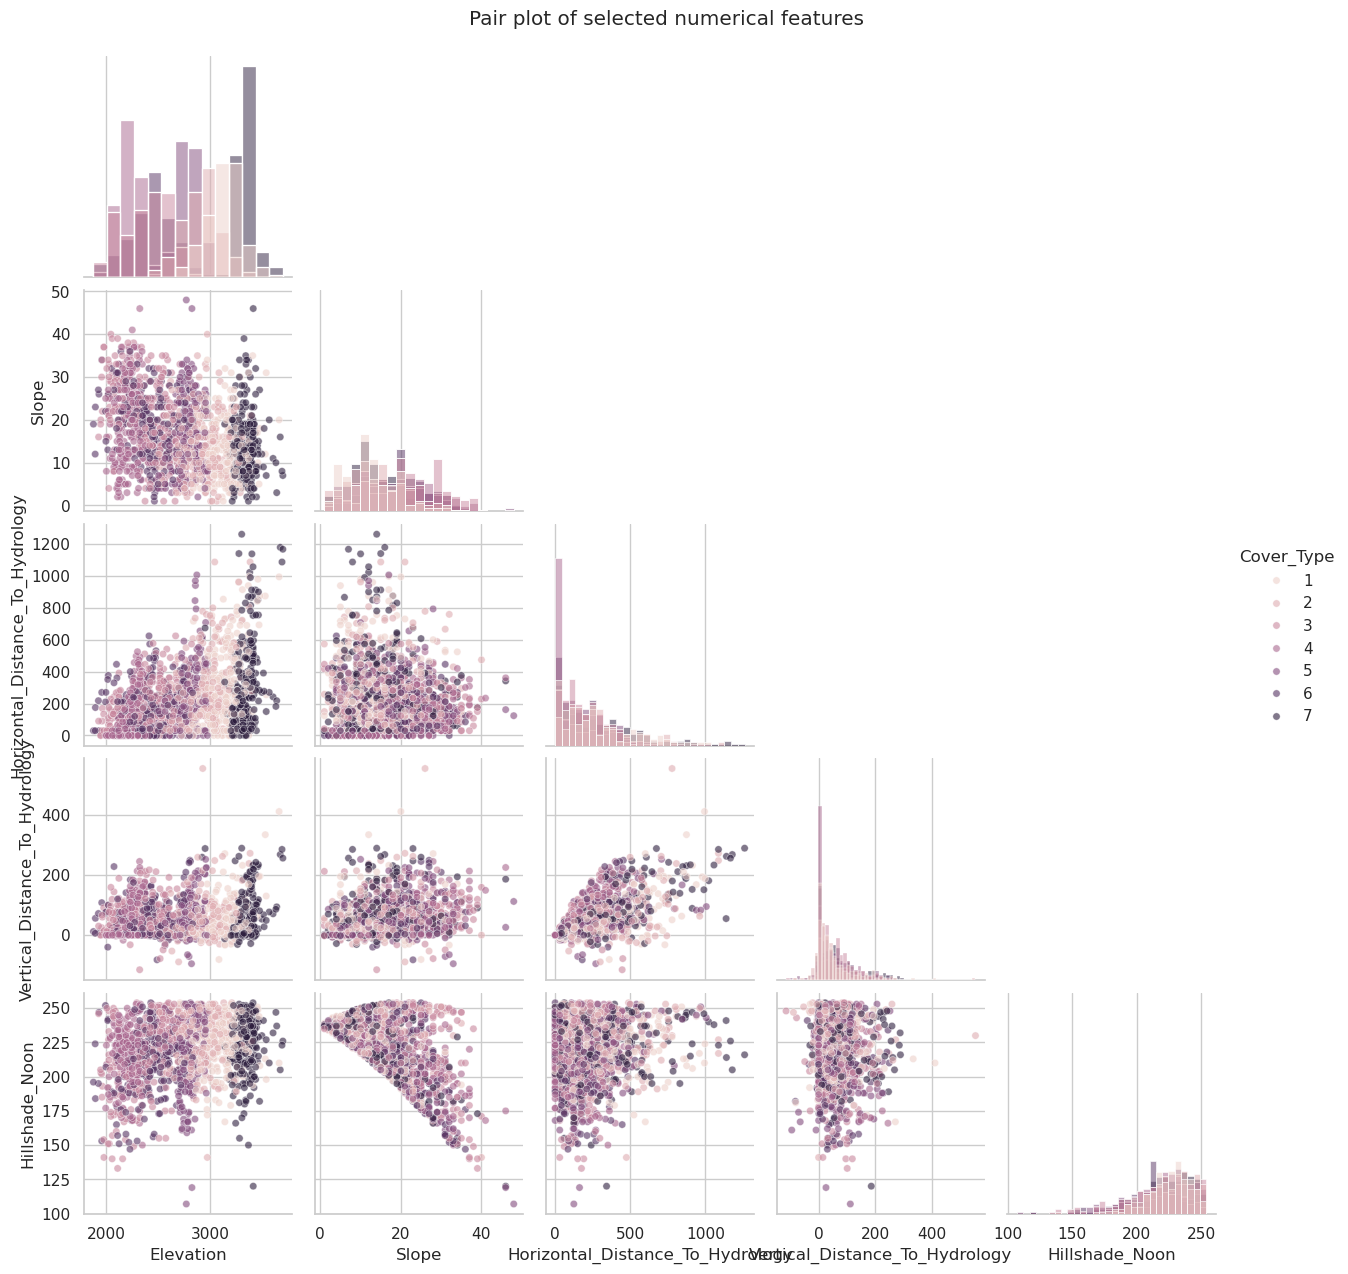

In [36]:
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns
    if c != TARGET
]

print("Numerical columns:")
print(numeric_cols)

# Start with the first few; replace these with the features YOU think are meaningful.
pair_cols = ["Elevation", "Slope", "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology", "Hillshade_Noon"]
print("\nPair-plot columns:", pair_cols)

if len(pair_cols) >= 2:
    plot_cols = pair_cols.copy()
    use_hue = False

    if TARGET in df.columns and df[TARGET].nunique(dropna=True) <= 10:
        plot_cols.append(TARGET)
        use_hue = True

    plot_df = df[plot_cols].dropna()
    if len(plot_df) > MAX_PAIRPLOT_ROWS:
        plot_df = plot_df.sample(MAX_PAIRPLOT_ROWS, random_state=42)

    if use_hue:
        g = sns.pairplot(plot_df, vars=pair_cols, hue=TARGET, corner=True, diag_kind="hist",
                         plot_kws={"alpha": 0.6, "s": 28})
    else:
        g = sns.pairplot(plot_df, vars=pair_cols, corner=True, diag_kind="hist",
                         plot_kws={"alpha": 0.6, "s": 28})

    g.fig.suptitle("Pair plot of selected numerical features", y=1.02)
    plt.show()
else:
    print("Need at least two numerical features for a pair plot.")

Features chosen because they cover the main physical traits: terrain (Elevation, Slope), water/human proximity (Hydrology, Roadways), and sunlight (Hillshade_Noon) without plotting all 3 hillshades or both hydrology distances.   

### Your turn — pair-plot observations

Write at least **2 observations** from your plot.

1. Elevation shows the strongest class separation, with different Cover_Type classes clustering at distinct elevation bands.
2. Slope and Hillshade_Noon show a non-linear relationship (steeper slopes create wider variance and lower minimum values in noon hillshade).
3. Horizontal_Distance_To_Hydrology and Horizontal_Distance_To_Roadways are heavily right-skewed with several extreme distance values, while Hillshade_Noon is left-skewed.

> **Project note:** today's pair plot is a quick exploratory view. It does **not** replace the project's later feature-by-feature distribution comparisons between target classes. Today, focus on understanding the dataset and finding the issues you need to address next.

## 5. Categorical features: use tables instead

A pair plot is designed for numerical variables. For categorical features, frequency tables are usually more useful.

For each important categorical feature, look at:
- how many observations are in each category,
- the percentage in each category,
- whether categories are very imbalanced,
- whether labels look inconsistent or need cleaning.


In [38]:
# Basic automatic list. Review it manually because some integer-coded columns may also be categorical.
categorical_cols = [
    c for c in df.columns
    if c.startswith("Wilderness_Area") or c.startswith("Soil_Type")
]

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols[:8]:
    print(f"\n--- {col} ---")
    table = pd.DataFrame({
        "Count": df[col].value_counts(dropna=False),
        "Percent": (df[col].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    display(table.head(15))

Categorical columns:
['Wilderness_Area1', 'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5', 'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10', 'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14', 'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18', 'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22', 'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26', 'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30', 'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34', 'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38', 'Soil_Type39', 'Soil_Type40']

--- Wilderness_Area1 ---


,Count,Percent
Wilderness_Area1,,
0,11523,76.2
1,3597,23.8



--- Wilderness_Area2 ---


,Count,Percent
Wilderness_Area2,,
0,14621,96.7
1,499,3.3



--- Wilderness_Area3 ---


,Count,Percent
Wilderness_Area3,,
0,8771,58.0
1,6349,42.0


... (6 outputs left out)


--- Soil_Type3 ---


,Count,Percent
Soil_Type3,,
0,14158,93.6
1,962,6.4



--- Soil_Type4 ---


,Count,Percent
Soil_Type4,,
0,14277,94.4
1,843,5.6


- Wilderness Areas: Wilderness_Area3 (6349 rows / 41.99%) and Wilderness_Area4 (4675 rows / 30.92%) make up nearly 73% of the dataset, whereas Wilderness_Area2 is rare (499 rows / 3.30%). Wilderness_Area4 (Cache la Poudre) is strongly associated with lower elevation classes (Cover_Type 3, 4, and 6) and contains zero instances of classes 1, 5, or 7.
- Soil Types: Highly imbalanced across the 40 binary columns. Soil_Type10 (2142 rows) and Soil_Type29 (1291 rows) are the most common, whereas Soil_Type7 and Soil_Type15 never appear (0 rows) and several others (Soil_Type8, Soil_Type25, Soil_Type28, Soil_Type36) appear less than 15 times.

### Optional: categorical feature vs. target

If the target is categorical, a cross-tab can help you see whether target outcomes differ across categories.

This is an exploratory step — it helps you notice patterns worth investigating later.


In [40]:
if TARGET in df.columns and df[TARGET].nunique(dropna=True) <= 10 and categorical_cols:
    example_cat = categorical_cols[0]   # Change this to a meaningful categorical feature.
    print(f"Cross-tab: {example_cat} vs {TARGET}")
    display(pd.crosstab(df[example_cat], df[TARGET], normalize="index").round(3))
else:
    print("Cross-tab skipped: no suitable categorical target/feature detected.")

Cross-tab: Wilderness_Area1 vs Cover_Type


Cover_Type,1,2,3,4,5,6,7
Wilderness_Area1,,,,,,,
0,0.095,0.089,0.187,0.187,0.113,0.187,0.140
1,0.295,0.315,0.000,0.000,0.238,0.000,0.152


## 6. Cleaning blockers are expected

It is completely okay if part of today's lab is spent cleaning or figuring out what needs to be cleaned.

Common issues to identify:
- missing values,
- duplicate rows,
- numbers stored as text,
- inconsistent category labels (`"Male"`, `"male"`, `"M"`),
- ID columns that should not be model features,
- date/time columns that need parsing,
- extreme values that may be errors or legitimate outliers,
- a strongly imbalanced target.

The goal today is to **identify** these issues. Do not automatically delete or change values without understanding them first.


In [30]:
# A few quick diagnostics. These do NOT automatically fix the data.
print("Rows:", len(df))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Columns with missing values:", int((df.isna().sum() > 0).sum()))

if TARGET in df.columns:
    print("\nTarget distribution:")
    target_summary = pd.DataFrame({
        "count": df[TARGET].value_counts(dropna=False),
        "percent": (df[TARGET].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    display(target_summary)

Rows: 15120


Duplicate rows: 0
Columns with missing values: 0

Target distribution:


,count,percent
Cover_Type,,
5,2160,14.3
2,2160,14.3
1,2160,14.3
7,2160,14.3
3,2160,14.3
6,2160,14.3
4,2160,14.3


## 7. End-of-lab checkpoint

Before you leave, be able to answer these questions for **your own dataset**.

### A. What is your target, and how balanced are the classes?
Write it here: The target is the 7 target classes (Cover_Type) and they are perfectly balanced (2160 samples / 14.3% each)


### B. What are 3 things you learned about the dataset?
1. There's 0 missing values and 0 duplicate rows.
2. Elevation is the strongest numerical feature that seperates the different Cover_Type classes
3. The bulk of the features are Wilderness_Area and Soil_Type. There are 44 of them split into binary columns. Soil_Type7 and Soil_Type15 are completely empty.

### C. What is 1 issue you need to fix before modeling?
- Wilderness_Area1–4 and Soil_Type1–40 are fragmented across 44 separate binary columns. There is a lot of room for condensing them down, same for some of the distance classes.

### D. What will you do next?
- Drop empty soil columns (Soil_Type7, Soil_Type15) combine the Wilderness_Area and Soil_Type columns and consider combining Horizontal and Vertical_Distance_To_Hydrology into total distance to water and combining similar Cover_Type classes.

You should now have a much clearer picture of what is actually in your data and what needs to happen before model training.


## 8. Optional: save your feature table

Save a copy of the feature summary so you can keep improving it as you learn more about the dataset.


In [41]:
OUTPUT_FEATURE_TABLE = "feature_summary.csv"
feature_table.to_csv(OUTPUT_FEATURE_TABLE, index=False)
print(f"Saved: {OUTPUT_FEATURE_TABLE}")

Saved: feature_summary.csv
